**Part D - 2026 tariff scenarios**

Goal: forecast car share, days driven per car user, total car days per employee and annual parking revenue at daily fees of **CHF 5, 6, 8 and 10**, starting from the 2025 situation at CHF 4.

Approach: every forecast starts from the Lausanne 2025 baseline and applies a constant-elasticity rule, separately for the extensive margin (car share) and the intensive margin (days per car user). The elasticities come from Parts B and C (Tables B3(c) and C2(c)), re-estimated below with the same sample, controls and clustering. 

Decisions to state in the report:
* **Site:** Lausanne only (the only site where the fee changed, so the only site with an estimated response). Sion stays at CHF 2 and is not forecast.
* **Days rule:** the one implausible value (7.4 days) is capped at 5, as in Part C.
* **Central elasticities:** from the specification with Sion as comparison site and controls (B3(c), C2(c)).

In [1]:
# packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

DATA_PATH = "parking_data_clean.csv"
TRANSIT_PATH = "transit_access.csv"

WEEKS = 46                      # working weeks per year (project guidelines)
BASE_FEE = 4.0                  # 2025 fee at Lausanne
TARIFFS = [4, 5, 6, 8, 10]      # CHF per day; 4 = 2025 baseline
LN2 = np.log(2)

raw = pd.read_csv(DATA_PATH)
ta = pd.read_csv(TRANSIT_PATH)

# same merge and days rule as Part C
df = (raw.drop(columns=["transit_group", "transit_score"], errors="ignore")
         .merge(ta[["home_commune", "site", "transit_score", "transit_group"]],
                on=["home_commune", "site"], how="left", validate="m:1"))
df.loc[df["car_days_per_week"] > 5, "car_days_per_week"] = 5.0      # one value of 7.4 capped at 5
df["car_user"] = df["car_days_per_week"] > 0
assert df["transit_group"].notna().all(), "some communes are missing from transit_access.csv"
print("rows:", len(df), "| car-user rows:", int(df["car_user"].sum()))

rows: 2000 | car-user rows: 1022


In [2]:
# table helpers (same look as Tables B1-B3 and C1-C3)
plt.rcParams.update({"font.family": "serif", "font.serif": ["STIXGeneral", "DejaVu Serif"]})

def booktabs(t, title, fname, note="", col_w=1.7, label_w=1.6, row_h=0.4, header_h=0.8,
             header_fs=10, body_fs=11):
    n_rows, n_cols = t.shape
    widths = [col_w] * n_cols if np.isscalar(col_w) else list(col_w)
    xs = label_w + np.concatenate([[0], np.cumsum(widths)])
    width = xs[-1]
    height = header_h + row_h * n_rows + 1.2
    fig, ax = plt.subplots(figsize=(width, height))
    ax.set_xlim(0, width); ax.set_ylim(0, height); ax.axis("off")
    top = height - 0.6; body_top = top - header_h; bottom = body_top - row_h * n_rows
    for j, c in enumerate(t.columns):
        ax.text((xs[j] + xs[j+1]) / 2, top - header_h / 2, c, ha="center", va="center",
                weight="bold", fontsize=header_fs, linespacing=1.1)
    for i, (lab, row) in enumerate(t.iterrows()):
        y = body_top - row_h * (i + 0.5)
        ax.text(0.1, y, lab, ha="left", va="center", fontsize=body_fs)
        for j, v in enumerate(row):
            ax.text((xs[j] + xs[j+1]) / 2, y, str(v), ha="center", va="center", fontsize=body_fs)
    ax.hlines(top, 0, width, color="black", lw=1.6)
    ax.hlines(body_top, 0, width, color="black", lw=0.7)
    ax.hlines(bottom, 0, width, color="black", lw=1.6)
    ax.text(width / 2, height - 0.2, title, ha="center", va="center", fontsize=12, weight="bold")
    if note:
        ax.text(0, bottom - 0.2, note, ha="left", va="top", fontsize=8.5)
    plt.savefig(fname, dpi=300, bbox_inches="tight")
    plt.show()

def booktabs_panels(panels, headers, title, note, fname, label_w=3.2, col_w=1.35, row_h=0.36):
    """panels: dict panel_name -> DataFrame of strings (rows = scenarios, columns = tariffs)."""
    rows = []
    for p, tab in panels.items():
        rows.append(("panel", p, None))
        for lab, r in tab.iterrows():
            rows.append(("row", lab, list(r.values)))
    n_cols = len(headers)
    n_hdr = 1.4 * row_h
    width = label_w + col_w * n_cols
    height = n_hdr + row_h * len(rows) + 1.6
    fig, ax = plt.subplots(figsize=(width, height))
    ax.set_xlim(0, width); ax.set_ylim(0, height); ax.axis("off")
    top = height - 0.7
    xc = lambda j: label_w + col_w * (j + 0.5)
    ax.text(width / 2, height - 0.25, title, ha="center", va="center", fontsize=12, weight="bold")
    for j, h in enumerate(headers):
        ax.text(xc(j), top - n_hdr / 2, h, ha="center", va="center", weight="bold", fontsize=10)
    ax.hlines(top, 0, width, color="black", lw=1.6)
    ax.hlines(top - n_hdr, 0, width, color="black", lw=0.7)
    y = top - n_hdr
    for k, (kind, label, vals) in enumerate(rows):
        yc = y - row_h / 2
        if kind == "panel":
            if k > 0:
                ax.hlines(y, 0, width, color="black", lw=0.4)
            ax.text(0.05, yc, label, ha="left", va="center", fontsize=10, style="italic", weight="bold")
        else:
            ax.text(0.3, yc, label, ha="left", va="center", fontsize=10)
            for j, v in enumerate(vals):
                ax.text(xc(j), yc, v, ha="center", va="center", fontsize=10)
        y -= row_h
    ax.hlines(y, 0, width, color="black", lw=1.6)
    ax.text(0, y - 0.3, note, ha="left", va="top", fontsize=8.5)
    plt.savefig(fname, dpi=300, bbox_inches="tight")
    plt.show()

**1. Baseline: Lausanne 2025 at CHF 4**

All forecasts are measured from here. Car share is the mean of the 0/1 indicator `car_user`; days per car user is the mean of `car_days_per_week` among car users only; car days per employee is the mean over all employees (non-drivers count as 0 days). Car days per employee = car share x days per car user.

In [3]:
L25 = df[(df["site"] == "Lausanne") & (df["year"] == 2025)]
N = len(L25)
share0 = L25["car_user"].mean()                                         # car share
dpu0 = L25.loc[L25["car_user"], "car_days_per_week"].mean()            # days per car user
dpe0 = L25["car_days_per_week"].mean()                                  # car days per employee
rev0 = BASE_FEE * WEEKS * dpe0 * N                                      # annual revenue (CHF)

assert abs(share0 * dpu0 - dpe0) < 1e-9
print(f"N = {N}")
print(f"car share         = {100*share0:.1f} %")
print(f"days per car user = {dpu0:.2f}")
print(f"car days per empl.= {dpe0:.2f}")
print(f"annual revenue    = CHF {rev0:,.0f}")

N = 800
car share         = 43.9 %
days per car user = 3.45
car days per empl.= 1.51
annual revenue    = CHF 222,990


**2. Elasticities: where they come from**

* **Extensive margin.** Table B3(c) is a linear probability model, `uses_car ~ log(fee) + site + year + controls`. Its coefficient `b` is the change in the *probability* of driving per unit of log fee. Doubling the fee changes the car share by `b x ln 2` percentage points. To turn this into an elasticity we compare the observed 2025 share with the share that would have prevailed *without* the fee increase (observed share minus `b x ln 2`; `b` is negative). The elasticity is the log ratio of the two shares divided by ln 2. This conversion is our own step; B3 does not report an elasticity.
* **Intensive margin.** Table C2(c) regresses `log(car days)` on `log(fee)` among car users, so its coefficient is already an elasticity.
* **Raw values.** Tables B2 and C1 give the plain Lausanne before-after elasticities (no comparison site, no controls). They are used as an alternative in the sensitivity check.

In [4]:
def fit(formula, data):
    # cluster by employee: each person appears in two years (same as Parts B and C)
    return smf.ols(formula, data).fit(cov_type="cluster", cov_kwds={"groups": data["employee_id"]})

df["log_fee"] = np.log(df["parking_fee_chf"])
df["log_inc"] = np.log(df["gross_income_chf"])
need = ["uses_car", "log_fee", "site", "year", "transit_score", "log_inc",
        "n_children", "distance_km", "age", "gender", "fte"]               # same list as Table B3
d = df.dropna(subset=need).copy()                                          # Part B estimation sample

d["inc10k_c"] = d["gross_income_chf"] / 1e4 - (d["gross_income_chf"] / 1e4).mean()
d["score_c"] = d["transit_score"] - d["transit_score"].mean()
d["kid1"] = (d["n_children"] == 1).astype(int)                            # reference: 0 children
d["kid2"] = (d["n_children"] == 2).astype(int)
ctrl = "score_c + inc10k_c + kid1 + kid2 + distance_km + age + C(gender) + fte"

# extensive margin: Table B3(c)
m_ext = fit(f"uses_car ~ log_fee + C(site) + C(year) + {ctrl}", d)
b, se_b = m_ext.params["log_fee"], m_ext.bse["log_fee"]

# intensive margin: Table C2(c)  (car users only; coefficient = elasticity)
dc = d[d["car_user"]].copy()
dc["log_days"] = np.log(dc["car_days_per_week"])
m_int = fit(f"log_days ~ log_fee + C(site) + C(year) + {ctrl}", dc)
e_int_c, se_int = m_int.params["log_fee"], m_int.bse["log_fee"]

def ext_elasticity(coef):
    """Elasticity of the car share implied by a LPM coefficient on log(fee)."""
    share_without_rise = share0 - coef * LN2          # 2025 car share if the fee had stayed at CHF 2
    return np.log(share0 / share_without_rise) / LN2

e_ext_c = ext_elasticity(b)

# raw before-after elasticities (Tables B2 and C1)
L24 = df[(df["site"] == "Lausanne") & (df["year"] == 2024)]
e_ext_raw = np.log(share0 / L24["car_user"].mean()) / LN2
e_int_raw = np.log(dpu0 / L24.loc[L24["car_user"], "car_days_per_week"].mean()) / LN2

print(f"B3(c): coefficient on log(fee) = {b:.3f} (SE {se_b:.3f}) -> doubling = {100*b*LN2:.1f} pp")
print(f"       share without the rise = {100*(share0 - b*LN2):.1f} %  -> extensive elasticity = {e_ext_c:.3f}")
print(f"C2(c): intensive elasticity    = {e_int_c:.3f} (SE {se_int:.3f})")
print(f"raw B2 / C1 elasticities       = {e_ext_raw:.3f} / {e_int_raw:.3f}")
print(f"total elasticity (central)     = {e_ext_c + e_int_c:.3f}")

B3(c): coefficient on log(fee) = -0.188 (SE 0.023) -> doubling = -13.1 pp
       share without the rise = 56.9 %  -> extensive elasticity = -0.376
C2(c): intensive elasticity    = -0.142 (SE 0.021)
raw B2 / C1 elasticities       = -0.296 / -0.062
total elasticity (central)     = -0.518


**Choice of central elasticities**

*To adapt after team discussion.* The central forecast uses the extensive elasticity implied by Table B3(c) (about -0.38) and the intensive elasticity from Table C2(c) (about -0.14). 
Reasons: 

(i) both come from the specification that uses Sion as a comparison site, so the general rise in car use between 2024 and 2025 (visible in Sion, where the fee did not change) is not mistaken for part of the policy effect; 

(ii) the raw before-after values (-0.30 and -0.06) are too small for exactly this reason, and the raw intensive value is also biased upwards by composition: the employees who stopped driving were occasional drivers (about 3.1 days vs 3.7 days for those who kept driving, Table S1), so the remaining car users drive more on average; 

(iii) the within-person estimate for stayers in Part C (-0.16 net of the Sion trend) is close to the C2(c) value. The regression controls only for observed characteristics, so selection is accounted for only partly.

**3. Scenario engine and Table D1**

For a new fee `p` the ratio `r = p / 4` says how many times the 2025 fee it is. With constant elasticities:

* car share(p) = car share(4) x r^(e_ext)
* days per car user(p) = days per car user(4) x r^(e_int)
* car days per employee(p) = car share(p) x days per car user(p)
* annual revenue(p) = p x 46 weeks x car days per employee(p) x N

Revenue depends on total car days, not on the car share alone.

In [5]:
def scenario(p, e_ext=None, e_int=None, lpm_b=None):
    """Forecast at daily fee p from the 2025 baseline.
    Constant elasticities by default; if lpm_b is given the car share follows the linear
    probability form share0 + lpm_b * ln(p/4) (floored at 0) instead."""
    r = p / BASE_FEE
    share = max(share0 + lpm_b * np.log(r), 0.0) if lpm_b is not None else share0 * r ** e_ext
    dpu = dpu0 * r ** e_int
    dpe = share * dpu
    return {"fee": p, "share": share, "dpu": dpu, "dpe": dpe, "revenue": p * WEEKS * dpe * N}

central = pd.DataFrame([scenario(p, e_ext=e_ext_c, e_int=e_int_c) for p in TARIFFS])

# checks: the baseline row reproduces 2025, and the decomposition identity holds
assert abs(central.loc[0, "revenue"] - rev0) < 1e-6
assert abs(central.loc[0, "share"] - share0) < 1e-12
print(central.round(3))

   fee  share    dpu    dpe     revenue
0    4  0.439  3.453  1.515  222989.600
1    5  0.403  3.345  1.350  248309.120
2    6  0.377  3.259  1.228  271116.493
3    8  0.338  3.128  1.058  311439.078
4   10  0.311  3.030  0.942  346801.660


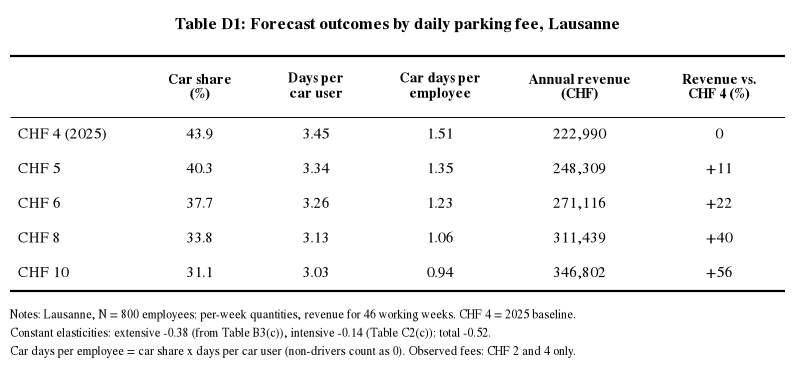

In [6]:
# Table D1 (central forecast)
D1 = pd.DataFrame({
    "Car share\n(%)": central["share"].map(lambda v: f"{100*v:.1f}"),
    "Days per\ncar user": central["dpu"].map(lambda v: f"{v:.2f}"),
    "Car days per\nemployee": central["dpe"].map(lambda v: f"{v:.2f}"),
    "Annual revenue\n(CHF)": central["revenue"].map(lambda v: f"{v:,.0f}"),
    "Revenue vs.\nCHF 4 (%)": (100 * (central["revenue"] / rev0 - 1)).map(lambda v: "0" if abs(v) < 0.5 else f"{v:+.0f}"),
})
D1.index = [f"CHF {p}" + (" (2025)" if p == 4 else "") for p in TARIFFS]

note = (f"Notes: Lausanne, N = {N} employees; per-week quantities, revenue for {WEEKS} working weeks. CHF 4 = 2025 baseline.\n"
        f"Constant elasticities: extensive {e_ext_c:.2f} (from Table B3(c)), intensive {e_int_c:.2f} (Table C2(c)); total {e_ext_c+e_int_c:.2f}.\n"
        "Car days per employee = car share x days per car user (non-drivers count as 0). Observed fees: CHF 2 and 4 only.")
booktabs(D1, "Table D1: Forecast outcomes by daily parking fee, Lausanne", "table_D1.png", note=note,
         col_w=[1.5, 1.5, 1.7, 1.9, 1.7], label_w=1.7, row_h=0.45)

**Comment (D1)**

*To write after the team has agreed on the central elasticities.* Points to cover: the car share falls from 43.9% at CHF 4 to about 37.7% at CHF 6 and 31.1% at CHF 10; days per car user fall only slightly (3.45 to 3.26 at CHF 6); total car days per employee fall by about 19% at CHF 6 and 38% at CHF 10; revenue rises at every tariff because the total elasticity (about -0.52) is smaller than 1 in absolute value (revenue elasticity = 1 + total elasticity, about +0.48), so higher fees raise revenue even as car use falls. The tariff with the highest revenue is therefore not automatically the best choice (see Part F).

**4. Sensitivity check**

Five variants of the same forecast:
* **Central** as above.
* **Weak / strong response:** both elasticities at the ends of their 95% confidence interval (coefficient +/- 1.96 standard errors, clustered by employee). This captures statistical uncertainty only.
* **Lausanne-only (raw B2/C1):** the plain before-after elasticities, without the comparison site.
* **Linear-in-log share (LPM):** the car share follows the linear probability model of Table B3(c) directly (a fixed number of percentage points per unit of log fee), instead of a constant elasticity. This tests whether the functional form matters.

Central                      {'e_ext': -0.376, 'e_int': -0.142}
Weak response (95% CI)       {'e_ext': -0.293, 'e_int': -0.101}
Strong response (95% CI)     {'e_ext': -0.454, 'e_int': -0.184}
Lausanne-only (raw B2/C1)    {'e_ext': -0.296, 'e_int': -0.062}
Linear-in-log share (LPM)    {'lpm_b': -0.188, 'e_int': -0.142}


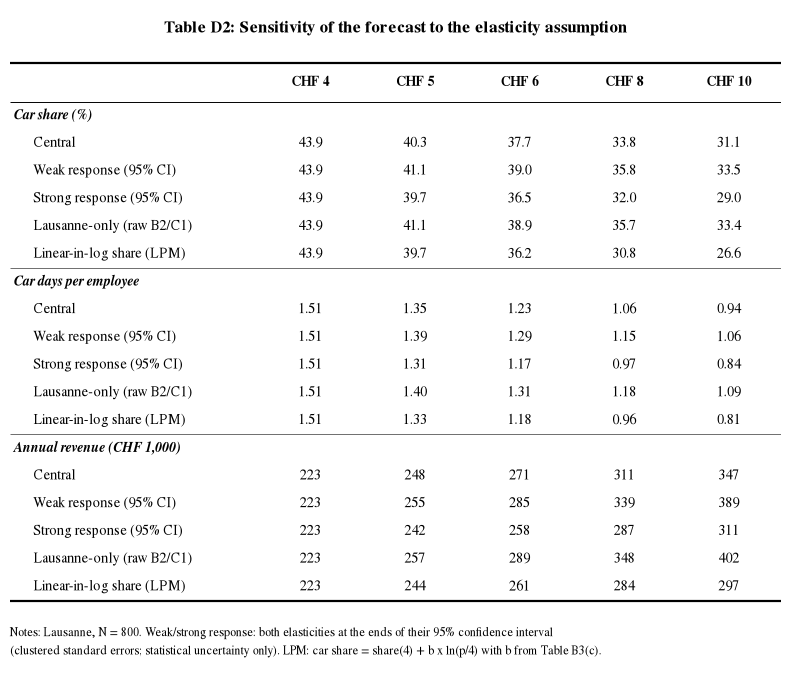

In [8]:
e_ext_strong = ext_elasticity(b - 1.96 * se_b)       # stronger response
e_ext_weak = ext_elasticity(b + 1.96 * se_b)         # weaker response
SC = {
    "Central": dict(e_ext=e_ext_c, e_int=e_int_c),
    "Weak response (95% CI)": dict(e_ext=e_ext_weak, e_int=e_int_c + 1.96 * se_int),
    "Strong response (95% CI)": dict(e_ext=e_ext_strong, e_int=e_int_c - 1.96 * se_int),
    "Lausanne-only (raw B2/C1)": dict(e_ext=e_ext_raw, e_int=e_int_raw),
    "Linear-in-log share (LPM)": dict(lpm_b=b, e_int=e_int_c),
}
res = pd.concat([pd.DataFrame([scenario(p, **kw) for p in TARIFFS]).assign(scenario=name)
                 for name, kw in SC.items()], ignore_index=True)

for name, kw in SC.items():
    print(f"{name:28s}", {k: round(float(v), 3) for k, v in kw.items()})

def wide(col, scale, fmt):
    w = res.pivot(index="scenario", columns="fee", values=col).loc[list(SC.keys())] * scale
    w = w.map(lambda v: fmt.format(v))
    w.columns = [f"CHF {c}" for c in w.columns]
    w.index.name = None
    return w

panels = {"Car share (%)": wide("share", 100, "{:.1f}"),
          "Car days per employee": wide("dpe", 1, "{:.2f}"),
          "Annual revenue (CHF 1,000)": wide("revenue", 1e-3, "{:,.0f}")}

note = ("Notes: Lausanne, N = 800. Weak/strong response: both elasticities at the ends of their 95% confidence interval\n"
        "(clustered standard errors; statistical uncertainty only). LPM: car share = share(4) + b x ln(p/4) with b from Table B3(c).")
booktabs_panels(panels, [f"CHF {p}" for p in TARIFFS], "Table D2: Sensitivity of the forecast to the elasticity assumption",
                note, "table_D2.png")

**Comment (D2)**

*To write.* Up to CHF 6 all variants lie close together (car share between 36% and 39%, revenue between CHF 261,000 and 289,000). The spread widens quickly beyond that: at CHF 10 the car share ranges from about 27% (LPM form) to 33% (raw elasticities), and revenue from about CHF 297,000 to 402,000. Two things drive this: the size of the elasticity, and the functional form (a constant elasticity predicts a flatter decline in the car share at high fees than the linear-in-log form). Conclusion: for CHF 5-6 the forecast is robust; for CHF 8-10 the choice of assumption matters more than the point estimate.

**5. Figure D1**

Left: total car use (car days per employee per week). Right: annual revenue. The line is the central forecast, the grey band is the 95% confidence range of the elasticities (weak to strong response), and the dashed line is the linear-in-log alternative.

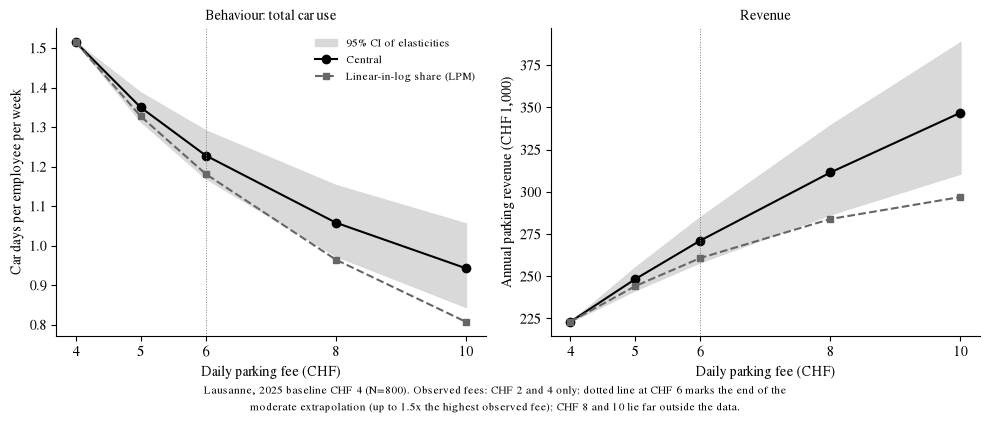

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
cen = res[res["scenario"] == "Central"]
lo = res[res["scenario"] == "Weak response (95% CI)"]
hi = res[res["scenario"] == "Strong response (95% CI)"]
alt = res[res["scenario"] == "Linear-in-log share (LPM)"]
for a, col, ylab in [(ax[0], "dpe", "Car days per employee per week"),
                     (ax[1], "revenue", "Annual parking revenue (CHF 1,000)")]:
    sc = 1e-3 if col == "revenue" else 1
    a.fill_between(cen["fee"], lo[col].values * sc, hi[col].values * sc, color="0.85", label="95% CI of elasticities")
    a.plot(cen["fee"], cen[col] * sc, "o-", color="black", label="Central")
    a.plot(alt["fee"], alt[col] * sc, "s--", color="0.4", ms=4, label="Linear-in-log share (LPM)")
    a.axvline(6, color="0.5", lw=0.7, ls=":")
    a.set_xticks(TARIFFS); a.set_xlabel("Daily parking fee (CHF)"); a.set_ylabel(ylab)
    a.spines[["top", "right"]].set_visible(False)
ax[0].legend(frameon=False, fontsize=8)
ax[0].set_title("Behaviour: total car use", fontsize=10)
ax[1].set_title("Revenue", fontsize=10)
fig.text(0.5, -0.04, "Lausanne, 2025 baseline CHF 4 (N=800). Observed fees: CHF 2 and 4 only; dotted line at CHF 6 marks the end of the\n"
         "moderate extrapolation (up to 1.5x the highest observed fee); CHF 8 and 10 lie far outside the data.",
         ha="center", fontsize=8)
plt.tight_layout()
plt.savefig("figure_D1.png", dpi=300, bbox_inches="tight")
plt.show()

**Assumptions, credible range and main risk**

*Draft for the report.*

**Assumptions.** The forecast assumes constant elasticities estimated from a single fee increase (CHF 2 to 4) in one year, that employees respond only to the fee (no other mobility policy changes, as stated in the case), that the 2025 Lausanne workforce and its composition stay as observed, and that the intensive and extensive margins combine multiplicatively.

**Credible range.** The data contain only two fee levels, CHF 2 and 4. CHF 5 and 6 (up to 1.5 times the highest observed fee) are a moderate extrapolation, and all sensitivity variants agree closely there. CHF 8 and 10 lie far outside the observed range; they should be read as indicative, and the variants diverge noticeably (Table D2).

**Main reason forecasts may fail.** The employees who still drive at CHF 4 are those with the fewest realistic alternatives (they live further away and were the more frequent drivers, Table S1). Further increases may therefore meet weaker responses than the constant elasticity assumes, which would make revenue higher but behaviour change smaller than forecast. In the other direction, a fee crossing a salient threshold could trigger a larger response than a smooth elasticity implies. The estimates also rest on a comparison with Sion that cannot be tested with only two years of data.